In [ ]:

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score, f1_score)
import warnings
warnings.filterwarnings('ignore')

BLUE   = '#4A90D9'
GREEN  = '#2ECC71'
RED    = '#E74C3C'
ORANGE = '#F39C12'
PURPLE = '#9B59B6'
BG     = '#F8F9FB'
CARD   = '#FFFFFF'

In [ ]:
print("=" * 60)
print("STEP 1: Load Dataset")
print("=" * 60)

df_raw = pd.read_csv('/content/sample_data/Dry_Eye_Dataset.csv')
print("Shape       :", df_raw.shape)
print("Columns     :", list(df_raw.columns))
print("\nFirst 5 rows:")
print(df_raw.head().to_string())



STEP 1: Load Dataset
Shape       : (20000, 26)
Columns     : ['Gender', 'Age', 'Sleep duration', 'Sleep quality', 'Stress level', 'Blood pressure', 'Heart rate', 'Daily steps', 'Physical activity', 'Height', 'Weight', 'Sleep disorder', 'Wake up during night', 'Feel sleepy during day', 'Caffeine consumption', 'Alcohol consumption', 'Smoking', 'Medical issue', 'Ongoing medication', 'Smart device before bed', 'Average screen time', 'Blue-light filter', 'Discomfort Eye-strain', 'Redness in eye', 'Itchiness/Irritation in eye', 'Dry Eye Disease']

First 5 rows:
  Gender  Age  Sleep duration  Sleep quality  Stress level Blood pressure  Heart rate  Daily steps  Physical activity  Height  Weight Sleep disorder Wake up during night Feel sleepy during day Caffeine consumption Alcohol consumption Smoking Medical issue Ongoing medication Smart device before bed  Average screen time Blue-light filter Discomfort Eye-strain Redness in eye Itchiness/Irritation in eye Dry Eye Disease
0      F   24      

In [ ]:
print("\n" + "=" * 60)
print("STEP 2: Exploratory Data Analysis (EDA)")
print("=" * 60)

print("\nData Types:")
print(df_raw.dtypes)
print("\nMissing Values:")
print(df_raw.isnull().sum())
print("\nDuplicate Rows:", df_raw.duplicated().sum())
print("\nStatistical Summary:")
print(df_raw.describe())
print("\nTarget Distribution:")
print(df_raw['Dry Eye Disease'].value_counts())




STEP 2: Exploratory Data Analysis (EDA)

Data Types:
Gender                          object
Age                              int64
Sleep duration                 float64
Sleep quality                    int64
Stress level                     int64
Blood pressure                  object
Heart rate                       int64
Daily steps                      int64
Physical activity                int64
Height                           int64
Weight                           int64
Sleep disorder                  object
Wake up during night            object
Feel sleepy during day          object
Caffeine consumption            object
Alcohol consumption             object
Smoking                         object
Medical issue                   object
Ongoing medication              object
Smart device before bed         object
Average screen time            float64
Blue-light filter               object
Discomfort Eye-strain           object
Redness in eye                  object
Itchiness/

In [ ]:
print("\n" + "=" * 60)
print("ACCURACY BEFORE PREPROCESSING")
print("=" * 60)

df_before = df_raw.copy()
df_before['Gender'] = df_before['Gender'].map({'F': 0, 'M': 1})
bp = df_before['Blood pressure'].str.split('/', expand=True).astype(int)
df_before['Systolic_BP']  = bp[0]
df_before['Diastolic_BP'] = bp[1]
df_before.drop(columns=['Blood pressure'], inplace=True)

yn_cols = [
    'Sleep disorder', 'Wake up during night', 'Feel sleepy during day',
    'Caffeine consumption', 'Alcohol consumption', 'Smoking',
    'Medical issue', 'Ongoing medication', 'Smart device before bed',
    'Blue-light filter', 'Discomfort Eye-strain', 'Redness in eye',
    'Itchiness/Irritation in eye', 'Dry Eye Disease'
]
for col in yn_cols:
    df_before[col] = df_before[col].map({'Y': 1, 'N': 0})

X_b = df_before.drop(columns=['Dry Eye Disease'])
y_b = df_before['Dry Eye Disease']
Xbtr, Xbte, ybtr, ybte = train_test_split(X_b, y_b, test_size=0.2, random_state=42)

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN'          : KNeighborsClassifier(),
    'Naive Bayes'  : GaussianNB()
}

before_acc = {}
for name, clf in models.items():
    clf.fit(Xbtr, ybtr)
    acc = round(accuracy_score(ybte, clf.predict(Xbte)) * 100, 2)
    before_acc[name] = acc
    print(f"  {name:20s}: {acc}%")



ACCURACY BEFORE PREPROCESSING
  Decision Tree       : 56.55%
  KNN                 : 59.42%
  Naive Bayes         : 68.25%


In [ ]:
print("\n" + "=" * 60)
print("STEP 3: Split Blood Pressure Column")
print("=" * 60)

df = df_raw.copy()
df[['Systolic_BP', 'Diastolic_BP']] = (
    df['Blood pressure'].str.split('/', expand=True).astype(int)
)
df.drop(columns=['Blood pressure'], inplace=True)
print(df[['Systolic_BP', 'Diastolic_BP']].head())




STEP 3: Split Blood Pressure Column
   Systolic_BP  Diastolic_BP
0          137            89
1          108            64
2          134            81
3          110            90
4           99            67


In [ ]:
print("\n" + "=" * 60)
print("STEP 4: Encode Gender  (F=0, M=1)")
print("=" * 60)

df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})
print(df['Gender'].value_counts())



STEP 4: Encode Gender  (F=0, M=1)
Gender
1    10028
0     9972
Name: count, dtype: int64


In [ ]:
print("\n" + "=" * 60)
print("STEP 5: Encode Yes/No Columns  (Y=1, N=0)")
print("=" * 60)

for col in yn_cols:
    df[col] = df[col].map({'Y': 1, 'N': 0})
print("Encoded columns:", yn_cols)
print(df[yn_cols].head(3))



STEP 5: Encode Yes/No Columns  (Y=1, N=0)
Encoded columns: ['Sleep disorder', 'Wake up during night', 'Feel sleepy during day', 'Caffeine consumption', 'Alcohol consumption', 'Smoking', 'Medical issue', 'Ongoing medication', 'Smart device before bed', 'Blue-light filter', 'Discomfort Eye-strain', 'Redness in eye', 'Itchiness/Irritation in eye', 'Dry Eye Disease']
   Sleep disorder  Wake up during night  Feel sleepy during day  \
0               1                     0                       0   
1               0                     0                       0   
2               1                     1                       0   

   Caffeine consumption  Alcohol consumption  Smoking  Medical issue  \
0                     0                    0        0              1   
1                     0                    1        0              1   
2                     1                    1        0              0   

   Ongoing medication  Smart device before bed  Blue-light filter  \
0     

In [ ]:
print("\n" + "=" * 60)
print("STEP 6: Feature Engineering — Add BMI")
print("=" * 60)

df['BMI'] = (df['Weight'] / (df['Height'] / 100) ** 2).round(2)
print(df[['Height', 'Weight', 'BMI']].head())



STEP 6: Feature Engineering — Add BMI
   Height  Weight    BMI
0     161      69  26.62
1     164      87  32.35
2     179      94  29.34
3     160      77  30.08
4     179      99  30.90


In [ ]:
print("\n" + "=" * 60)
print("STEP 7: Outlier Detection (IQR Method)")
print("=" * 60)

num_check = ['Age', 'Heart rate', 'Daily steps', 'Sleep duration', 'Average screen time']
for col in num_check:
    Q1  = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    print(f"  {col:30s}: {len(outliers)} outliers")




STEP 7: Outlier Detection (IQR Method)
  Age                           : 0 outliers
  Heart rate                    : 0 outliers
  Daily steps                   : 0 outliers
  Sleep duration                : 0 outliers
  Average screen time           : 0 outliers


In [ ]:
print("\n" + "=" * 60)
print("STEP 8: Min-Max Normalization  →  range [0, 1]")
print("=" * 60)

num_cols = [
    'Age', 'Sleep duration', 'Sleep quality', 'Stress level',
    'Heart rate', 'Daily steps', 'Physical activity',
    'Height', 'Weight', 'Average screen time',
    'Systolic_BP', 'Diastolic_BP', 'BMI'
]
scaler = MinMaxScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
df[num_cols] = df[num_cols].round(4)
print("Min and Max after scaling:")
print(df[num_cols].agg(['min', 'max']))




STEP 8: Min-Max Normalization  →  range [0, 1]
Min and Max after scaling:
     Age  Sleep duration  Sleep quality  Stress level  Heart rate  \
min  0.0             0.0            0.0           0.0         0.0   
max  1.0             1.0            1.0           1.0         1.0   

     Daily steps  Physical activity  Height  Weight  Average screen time  \
min          0.0                0.0     0.0     0.0                  0.0   
max          1.0                1.0     1.0     1.0                  1.0   

     Systolic_BP  Diastolic_BP  BMI  
min          0.0           0.0  0.0  
max          1.0           1.0  1.0  


In [ ]:
print("Final Shape:", df.shape)


Final Shape: (20000, 28)


In [ ]:
print("\n" + "=" * 60)
print("ACCURACY AFTER PREPROCESSING")
print("=" * 60)

X_a = df.drop(columns=['Dry Eye Disease'])
y_a = df['Dry Eye Disease']
Xatr, Xate, yatr, yate = train_test_split(X_a, y_a, test_size=0.2, random_state=42)

after_acc, after_prec, after_rec, after_f1, after_cv, after_pred = {}, {}, {}, {}, {}, {}

for name, clf in models.items():
    clf2 = type(clf)(**clf.get_params())
    clf2.fit(Xatr, yatr)
    p = clf2.predict(Xate)
    after_acc[name]  = round(accuracy_score(yate, p)  * 100, 2)
    after_prec[name] = round(precision_score(yate, p) * 100, 2)
    after_rec[name]  = round(recall_score(yate, p)    * 100, 2)
    after_f1[name]   = round(f1_score(yate, p)        * 100, 2)
    cv = cross_val_score(type(clf)(**clf.get_params()), X_a, y_a, cv=5, scoring='accuracy')
    after_cv[name]   = round(cv.mean() * 100, 2)
    after_pred[name] = p
    print(f"  {name:20s}: Acc={after_acc[name]}%")




ACCURACY AFTER PREPROCESSING
  Decision Tree       : Acc=56.93%
  KNN                 : Acc=62.05%
  Naive Bayes         : Acc=69.15%


In [ ]:
print("\n" + "=" * 60)
print("STEP 10: Full Evaluation Report")
print("=" * 60)
print(f"\n{'Model':<20} {'Accuracy':>9} {'Precision':>10} {'Recall':>8} {'F1-Score':>9} {'CV (5-fold)':>12}")
print("-" * 72)
for name in models:
    print(f"{name:<20} {after_acc[name]:>8}% {after_prec[name]:>9}% "
          f"{after_rec[name]:>7}% {after_f1[name]:>8}% {after_cv[name]:>11}%")
print("=" * 72)



STEP 10: Full Evaluation Report

Model                 Accuracy  Precision   Recall  F1-Score  CV (5-fold)
------------------------------------------------------------------------
Decision Tree           56.93%     69.32%   64.61%    66.88%       57.01%
KNN                     62.05%     69.66%   77.31%    73.28%       61.84%
Naive Bayes             69.15%     69.82%   95.43%    80.64%       67.81%


In [ ]:
print("\n" + "=" * 60)
print("STEP 11: Before vs After Preprocessing Comparison")
print("=" * 60)
print(f"\n{'Model':<20} {'Before':>8} {'After':>8} {'Gain':>8}")
print("-" * 46)
for name in models:
    diff = round(after_acc[name] - before_acc[name], 2)
    sign = '+' if diff >= 0 else ''
    print(f"{name:<20} {before_acc[name]:>7}% {after_acc[name]:>7}% {sign}{diff:>6}%")
print("=" * 46)



STEP 11: Before vs After Preprocessing Comparison

Model                  Before    After     Gain
----------------------------------------------
Decision Tree          56.55%   56.93% +  0.38%
KNN                    59.42%   62.05% +  2.63%
Naive Bayes            68.25%   69.15% +   0.9%



STEP 12: Generating Visualizations


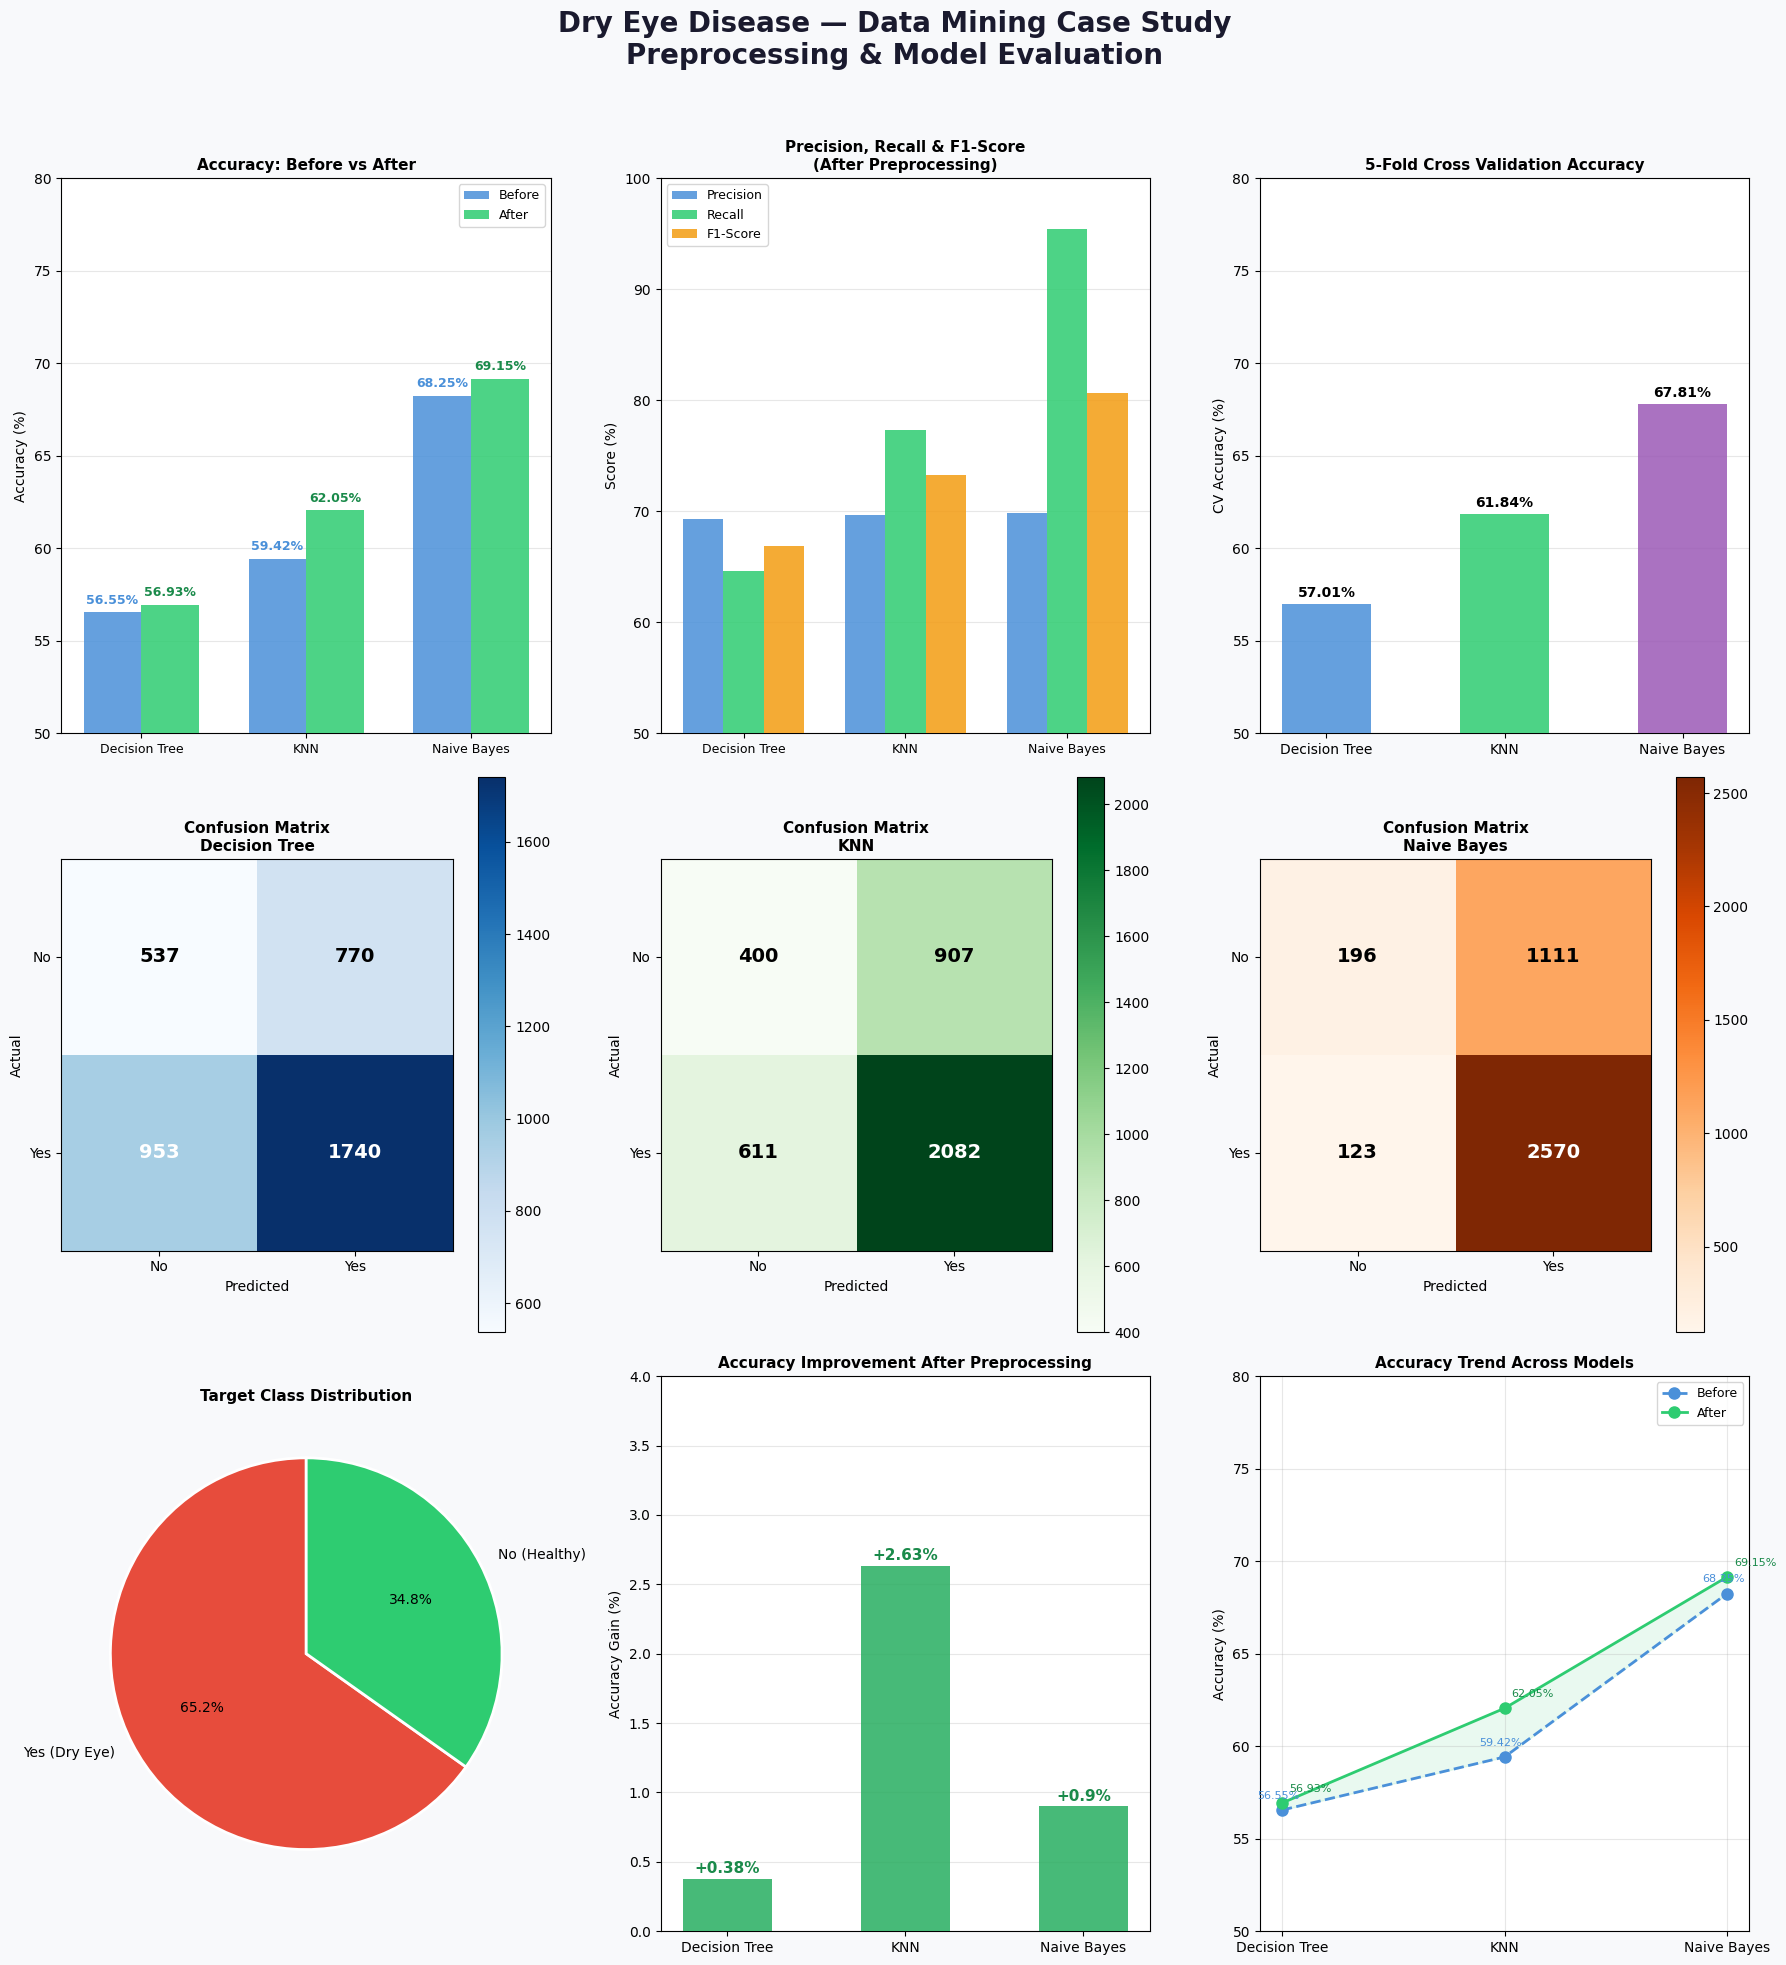

  Figure 1 displayed.


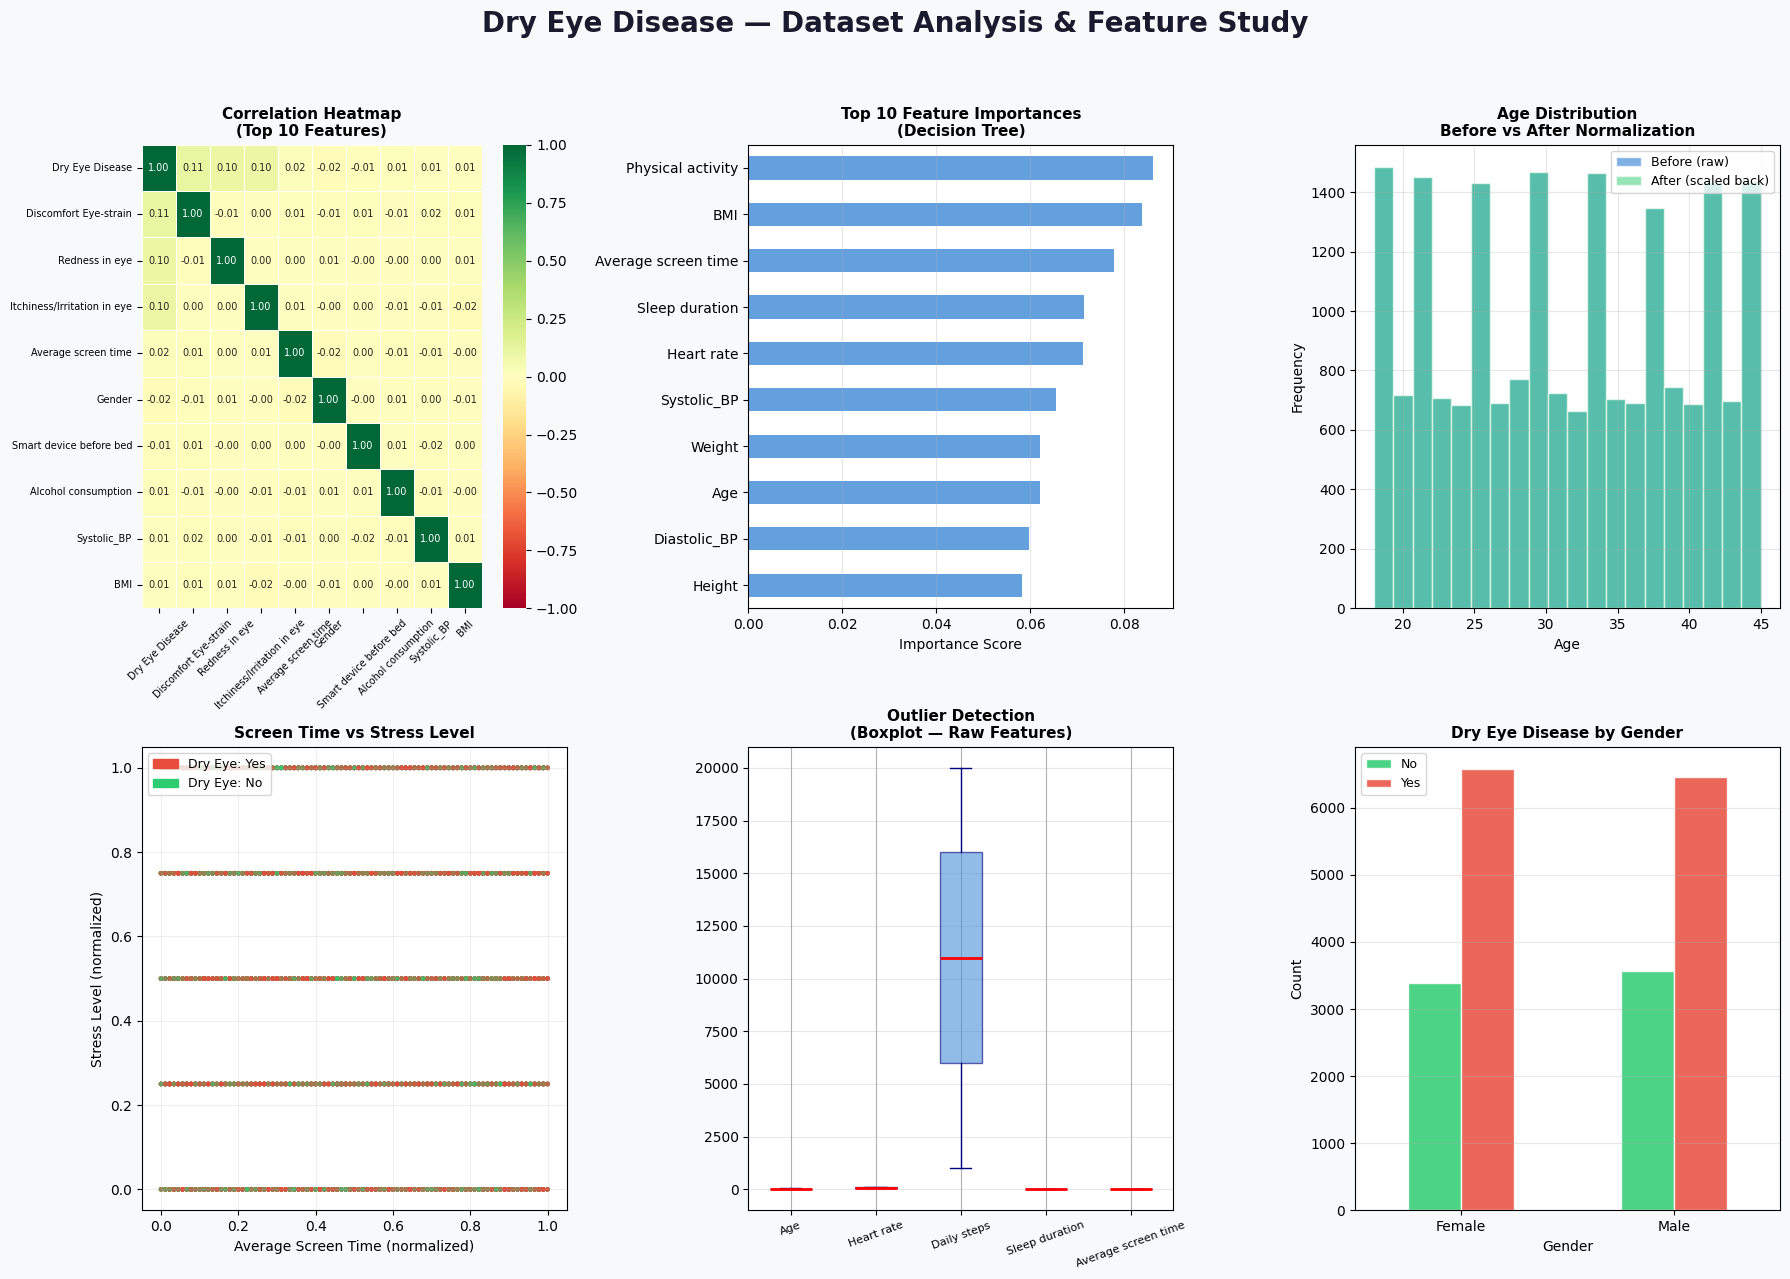

  Figure 2 displayed.


In [ ]:
%matplotlib inline

print("\n" + "=" * 60)
print("STEP 12: Generating Visualizations")
print("=" * 60)

names  = list(models.keys())
b_vals = [before_acc[n] for n in names]
a_vals = [after_acc[n]  for n in names]

fig1 = plt.figure(figsize=(18, 20))
fig1.patch.set_facecolor(BG)
fig1.suptitle('Dry Eye Disease — Data Mining Case Study\nPreprocessing & Model Evaluation',
              fontsize=20, fontweight='bold', y=0.98, color='#1a1a2e')

ax1 = fig1.add_subplot(3, 3, 1); ax1.set_facecolor(CARD)
x = np.arange(len(names)); w = 0.35
b1 = ax1.bar(x - w/2, b_vals, w, label='Before', color=BLUE,  alpha=0.85, zorder=3)
b2 = ax1.bar(x + w/2, a_vals, w, label='After',  color=GREEN, alpha=0.85, zorder=3)
for bar in b1:
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f'{bar.get_height()}%', ha='center', va='bottom', fontsize=9, color=BLUE, fontweight='bold')
for bar in b2:
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f'{bar.get_height()}%', ha='center', va='bottom', fontsize=9, color='#1a8a4a', fontweight='bold')
ax1.set_xticks(x); ax1.set_xticklabels(names, fontsize=9)
ax1.set_ylabel('Accuracy (%)'); ax1.set_title('Accuracy: Before vs After', fontweight='bold', fontsize=11)
ax1.set_ylim(50, 80); ax1.legend(fontsize=9); ax1.grid(axis='y', alpha=0.3, zorder=0)

ax2 = fig1.add_subplot(3, 3, 2); ax2.set_facecolor(CARD)
x2 = np.arange(len(names)); w2 = 0.25
ax2.bar(x2 - w2, [after_prec[n] for n in names], w2, label='Precision', color=BLUE,   alpha=0.85, zorder=3)
ax2.bar(x2,      [after_rec[n]  for n in names], w2, label='Recall',    color=GREEN,  alpha=0.85, zorder=3)
ax2.bar(x2 + w2, [after_f1[n]   for n in names], w2, label='F1-Score',  color=ORANGE, alpha=0.85, zorder=3)
ax2.set_xticks(x2); ax2.set_xticklabels(names, fontsize=9)
ax2.set_ylabel('Score (%)'); ax2.set_title('Precision, Recall & F1-Score\n(After Preprocessing)', fontweight='bold', fontsize=11)
ax2.set_ylim(50, 100); ax2.legend(fontsize=9); ax2.grid(axis='y', alpha=0.3, zorder=0)

ax3 = fig1.add_subplot(3, 3, 3); ax3.set_facecolor(CARD)
cv_vals = [after_cv[n] for n in names]
bars3 = ax3.bar(names, cv_vals, color=[BLUE, GREEN, PURPLE], alpha=0.85, zorder=3, width=0.5)
for bar, v in zip(bars3, cv_vals):
    ax3.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2,
             f'{v}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax3.set_ylabel('CV Accuracy (%)'); ax3.set_title('5-Fold Cross Validation Accuracy', fontweight='bold', fontsize=11)
ax3.set_ylim(50, 80); ax3.grid(axis='y', alpha=0.3, zorder=0)

cmaps = ['Blues', 'Greens', 'Oranges']
for idx, (name, cmap) in enumerate(zip(names, cmaps)):
    ax = fig1.add_subplot(3, 3, 4 + idx)
    cm = confusion_matrix(yate, after_pred[name])
    im = ax.imshow(cm, cmap=cmap)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['No', 'Yes']); ax.set_yticklabels(['No', 'Yes'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'Confusion Matrix\n{name}', fontweight='bold', fontsize=11)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=14,
                    fontweight='bold', color='white' if cm[i, j] > cm.max()/2 else 'black')
    plt.colorbar(im, ax=ax)

ax7 = fig1.add_subplot(3, 3, 7)
counts = df_raw['Dry Eye Disease'].value_counts()
ax7.pie(counts.values, labels=['Yes (Dry Eye)', 'No (Healthy)'], autopct='%1.1f%%',
        colors=[RED, GREEN], startangle=90, textprops={'fontsize': 10},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax7.set_title('Target Class Distribution', fontweight='bold', fontsize=11)

ax8 = fig1.add_subplot(3, 3, 8); ax8.set_facecolor(CARD)
diffs = [round(after_acc[n] - before_acc[n], 2) for n in names]
bars8 = ax8.bar(names, diffs, color='#27AE60', alpha=0.85, zorder=3, width=0.5)
for bar, d in zip(bars8, diffs):
    ax8.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
             f'+{d}%', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#1a8a4a')
ax8.set_ylabel('Accuracy Gain (%)'); ax8.set_title('Accuracy Improvement After Preprocessing', fontweight='bold', fontsize=11)
ax8.set_ylim(0, 4); ax8.grid(axis='y', alpha=0.3, zorder=0)

ax9 = fig1.add_subplot(3, 3, 9); ax9.set_facecolor(CARD)
ax9.plot(names, b_vals, 'o--', color=BLUE,  linewidth=2, markersize=8, label='Before', zorder=3)
ax9.plot(names, a_vals, 'o-',  color=GREEN, linewidth=2, markersize=8, label='After',  zorder=3)
for i, (n, b, a) in enumerate(zip(names, b_vals, a_vals)):
    ax9.annotate(f'{b}%', (i, b), textcoords='offset points', xytext=(-18, 8), fontsize=8, color=BLUE)
    ax9.annotate(f'{a}%', (i, a), textcoords='offset points', xytext=(5,   8), fontsize=8, color='#1a8a4a')
ax9.fill_between(range(len(names)), b_vals, a_vals, alpha=0.1, color=GREEN)
ax9.set_ylabel('Accuracy (%)'); ax9.set_title('Accuracy Trend Across Models', fontweight='bold', fontsize=11)
ax9.set_ylim(50, 80); ax9.legend(fontsize=9); ax9.grid(alpha=0.3, zorder=0)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
print("  Figure 1 displayed.")


fig2 = plt.figure(figsize=(18, 13))
fig2.patch.set_facecolor(BG)
fig2.suptitle('Dry Eye Disease — Dataset Analysis & Feature Study',
              fontsize=20, fontweight='bold', y=0.98, color='#1a1a2e')

ax1 = fig2.add_subplot(2, 3, 1)
top_features = df.corr()['Dry Eye Disease'].abs().nlargest(10).index
sns.heatmap(df[top_features].corr(), annot=True, fmt='.2f', cmap='RdYlGn',
            ax=ax1, linewidths=0.5, annot_kws={'size': 7}, vmin=-1, vmax=1)
ax1.set_title('Correlation Heatmap\n(Top 10 Features)', fontweight='bold', fontsize=11)
ax1.tick_params(axis='x', rotation=45, labelsize=7)
ax1.tick_params(axis='y', rotation=0,  labelsize=7)

ax2 = fig2.add_subplot(2, 3, 2); ax2.set_facecolor(CARD)
dt = DecisionTreeClassifier(random_state=42); dt.fit(Xatr, yatr)
feat_imp = pd.Series(dt.feature_importances_, index=X_a.columns).nlargest(10)
feat_imp.sort_values().plot(kind='barh', ax=ax2, color=BLUE, alpha=0.85)
ax2.set_xlabel('Importance Score')
ax2.set_title('Top 10 Feature Importances\n(Decision Tree)', fontweight='bold', fontsize=11)
ax2.grid(axis='x', alpha=0.3)

ax3 = fig2.add_subplot(2, 3, 3); ax3.set_facecolor(CARD)
ax3.hist(df_raw['Age'], bins=20, color=BLUE,  alpha=0.7, edgecolor='white', label='Before (raw)')
ax3.hist(df['Age'] * 27 + 18, bins=20, color=GREEN, alpha=0.5, edgecolor='white', label='After (scaled back)')
ax3.set_xlabel('Age'); ax3.set_ylabel('Frequency')
ax3.set_title('Age Distribution\nBefore vs After Normalization', fontweight='bold', fontsize=11)
ax3.legend(fontsize=9); ax3.grid(alpha=0.3)

ax4 = fig2.add_subplot(2, 3, 4); ax4.set_facecolor(CARD)
colors_s = df['Dry Eye Disease'].map({1: RED, 0: GREEN})
ax4.scatter(df['Average screen time'], df['Stress level'], c=colors_s, alpha=0.3, s=5)
ax4.set_xlabel('Average Screen Time (normalized)')
ax4.set_ylabel('Stress Level (normalized)')
ax4.set_title('Screen Time vs Stress Level', fontweight='bold', fontsize=11)
p1 = mpatches.Patch(color=RED,   label='Dry Eye: Yes')
p2 = mpatches.Patch(color=GREEN, label='Dry Eye: No')
ax4.legend(handles=[p1, p2], fontsize=9); ax4.grid(alpha=0.2)

ax5 = fig2.add_subplot(2, 3, 5); ax5.set_facecolor(CARD)
outlier_cols = ['Age', 'Heart rate', 'Daily steps', 'Sleep duration', 'Average screen time']
df_raw[outlier_cols].boxplot(
    ax=ax5, patch_artist=True,
    boxprops=dict(facecolor=BLUE, color='navy', alpha=0.6),
    medianprops=dict(color='red', linewidth=2),
    whiskerprops=dict(color='navy'), capprops=dict(color='navy'),
    flierprops=dict(marker='o', markerfacecolor=RED, markersize=3, alpha=0.5)
)
ax5.set_title('Outlier Detection\n(Boxplot — Raw Features)', fontweight='bold', fontsize=11)
ax5.tick_params(axis='x', rotation=20, labelsize=8)
ax5.grid(axis='y', alpha=0.3)

ax6 = fig2.add_subplot(2, 3, 6); ax6.set_facecolor(CARD)
grp = df_raw.groupby(['Gender', 'Dry Eye Disease']).size().unstack()
grp.plot(kind='bar', ax=ax6, color=[GREEN, RED], alpha=0.85, edgecolor='white')
ax6.set_xticklabels(['Female', 'Male'], rotation=0, fontsize=10)
ax6.set_ylabel('Count')
ax6.set_title('Dry Eye Disease by Gender', fontweight='bold', fontsize=11)
ax6.legend(['No', 'Yes'], fontsize=9); ax6.grid(axis='y', alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
print("  Figure 2 displayed.")



In [ ]:

!pip install streamlit -q
!npm install -g localtunnel -q

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
changed 22 packages in 1s
⠸
⠸3 packages are looking for funding
⠸  run `npm fund` for details
⠸

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Dry_Eye_Dataset.csv to Dry_Eye_Dataset (1).csv


In [ ]:
!pip install colab_xterm -q
!pip install streamlit -q

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score, f1_score)
import warnings
warnings.filterwarnings('ignore')

st.set_page_config(page_title="Dry Eye Disease", page_icon="👁️",
                   layout="wide", initial_sidebar_state="expanded")

BLUE='#4A90D9'; GREEN='#2ECC71'; RED='#E74C3C'
ORANGE='#F39C12'; PURPLE='#9B59B6'

st.markdown("""
<style>
  .hero{background:linear-gradient(135deg,#1a1a2e,#0f3460);border-radius:16px;
        padding:2.5rem 2rem;margin-bottom:2rem;color:white;}
  .hero h1{font-size:2.2rem;margin:0 0 0.5rem;}
  .hero p{opacity:0.75;margin:0;}
  .metric-card{background:white;border-radius:12px;padding:1.2rem;text-align:center;
               box-shadow:0 2px 12px rgba(0,0,0,0.07);
               border-top:4px solid var(--accent,#4A90D9);}
  .metric-card .val{font-size:2rem;font-weight:700;color:#1a1a2e;}
  .metric-card .lbl{font-size:0.78rem;color:#666;}
  .section-title{font-size:1.3rem;font-weight:700;color:#1a1a2e;
                 border-left:4px solid #4A90D9;padding-left:0.75rem;margin:1.5rem 0 1rem;}
  .info-box{background:#EBF5FB;border-left:4px solid #4A90D9;padding:0.8rem 1rem;
            border-radius:0 8px 8px 0;font-size:0.88rem;color:#1a4a6e;margin:0.5rem 0 1rem;}
</style>
""", unsafe_allow_html=True)

@st.cache_data
def load_raw():
    return pd.read_csv('Dry_Eye_Dataset.csv')

@st.cache_data
def run_pipeline(df_raw):
    TARGET = 'Dry Eye Disease'
    yn_cols = ['Sleep disorder','Wake up during night','Feel sleepy during day',
               'Caffeine consumption','Alcohol consumption','Smoking','Medical issue',
               'Ongoing medication','Smart device before bed','Blue-light filter',
               'Discomfort Eye-strain','Redness in eye',
               'Itchiness/Irritation in eye', TARGET]
    num_cols = ['Age','Sleep duration','Sleep quality','Stress level','Heart rate',
                'Daily steps','Physical activity','Height','Weight',
                'Average screen time','Systolic_BP','Diastolic_BP','BMI']

    db = df_raw.copy()
    db['Gender'] = db['Gender'].map({'F':0,'M':1})
    bp = db['Blood pressure'].str.split('/', expand=True).astype(int)
    db['Systolic_BP'] = bp[0]; db['Diastolic_BP'] = bp[1]
    db.drop(columns=['Blood pressure'], inplace=True)
    for c in yn_cols: db[c] = db[c].map({'Y':1,'N':0})
    db['BMI'] = (db['Weight']/(db['Height']/100)**2).round(2)
    Xb = db.drop(columns=[TARGET]); yb = db[TARGET]
    Xbtr,Xbte,ybtr,ybte = train_test_split(Xb,yb,test_size=0.2,random_state=42)

    da = df_raw.copy()
    da['Gender'] = da['Gender'].map({'F':0,'M':1})
    bp2 = da['Blood pressure'].str.split('/', expand=True).astype(int)
    da['Systolic_BP'] = bp2[0]; da['Diastolic_BP'] = bp2[1]
    da.drop(columns=['Blood pressure'], inplace=True)
    for c in yn_cols: da[c] = da[c].map({'Y':1,'N':0})
    da['BMI'] = (da['Weight']/(da['Height']/100)**2).round(2)

    outlier_cols = ['Age','Heart rate','Daily steps','Sleep duration','Average screen time']
    outlier_counts = {}
    for col in outlier_cols:
        Q1,Q3 = da[col].quantile(0.25), da[col].quantile(0.75)
        IQR = Q3-Q1
        outlier_counts[col] = int(((da[col]<Q1-1.5*IQR)|(da[col]>Q3+1.5*IQR)).sum())

    scaler = MinMaxScaler()
    da[num_cols] = scaler.fit_transform(da[num_cols]).round(4)

    Xa = da.drop(columns=[TARGET]); ya = da[TARGET]
    Xatr,Xate,yatr,yate = train_test_split(Xa,ya,test_size=0.2,random_state=42)

    models = {'Decision Tree': DecisionTreeClassifier(random_state=42),
              'KNN':           KNeighborsClassifier(),
              'Naive Bayes':   GaussianNB()}

    before_acc={}
    for name,clf in models.items():
        clf.fit(Xbtr,ybtr)
        before_acc[name]=round(accuracy_score(ybte,clf.predict(Xbte))*100,2)

    after_acc={};after_prec={};after_rec={};after_f1={};after_cv={};after_pred={};cms={}
    for name,clf in models.items():
        c2=type(clf)(**clf.get_params())
        c2.fit(Xatr,yatr); p=c2.predict(Xate)
        after_pred[name]=p
        after_acc[name] =round(accuracy_score(yate,p)*100,2)
        after_prec[name]=round(precision_score(yate,p)*100,2)
        after_rec[name] =round(recall_score(yate,p)*100,2)
        after_f1[name]  =round(f1_score(yate,p)*100,2)
        cv=cross_val_score(type(clf)(**clf.get_params()),Xa,ya,cv=5,scoring='accuracy')
        after_cv[name]  =round(cv.mean()*100,2)
        cms[name]       =confusion_matrix(yate,p)

    dt=DecisionTreeClassifier(random_state=42); dt.fit(Xatr,yatr)
    feat_imp=pd.Series(dt.feature_importances_,index=Xa.columns).nlargest(10)

    return (da, db, Xa, ya, before_acc, after_acc, after_prec, after_rec,
            after_f1, after_cv, after_pred, cms, feat_imp,
            outlier_counts, scaler, num_cols)

with st.sidebar:
    st.markdown("## 👁️ Navigation")
    page = st.radio("Go to", ["🏠 Overview","📂 Raw Dataset",
                               "🔧 Preprocessing Steps","📊 EDA & Visualizations",
                               "🤖 Model Evaluation","🔮 Predict"])
    st.markdown("---")
    st.caption("Dataset: Dry Eye Disease · 20,000 rows")
    st.caption("Models: Decision Tree · KNN · Naive Bayes")
    st.caption("Scaler: MinMaxScaler → [0, 1]")


df_raw = load_raw()
(da, db, Xa, ya, before_acc, after_acc, after_prec, after_rec,
 after_f1, after_cv, after_pred, cms, feat_imp,
 outlier_counts, scaler, num_cols) = run_pipeline(df_raw)
names = list(before_acc.keys())


if page == "🏠 Overview":
    st.markdown("<div class='hero'><h1>👁️ Dry Eye Disease</h1>"
                "<p>Data Mining Case Study — Preprocessing, EDA & Model Evaluation</p>"
                "</div>", unsafe_allow_html=True)

    best = max(after_acc, key=after_acc.get)
    c1,c2,c3,c4 = st.columns(4)
    for col,(accent,val,lbl) in zip([c1,c2,c3,c4],[
        ("#4A90D9","20,000","Total Records"),
        ("#2ECC71","28","Features After Engineering"),
        ("#E74C3C",f"{after_acc[best]}%",f"Best Accuracy ({best})"),
        ("#9B59B6","MinMaxScaler","Normalization Method")]):
        col.markdown(f"<div class='metric-card' style='--accent:{accent}'>"
                     f"<div class='val'>{val}</div><div class='lbl'>{lbl}</div>"
                     f"</div>", unsafe_allow_html=True)

    st.markdown("<div class='section-title'>Case Study Pipeline</div>",
                unsafe_allow_html=True)
    steps=[("📂","Data Loading","Import CSV · 20,000 rows × 26 cols"),
           ("🧹","Data Cleaning","Remove duplicates, check nulls"),
           ("⚙️","Feature Eng.","Parse BP → Systolic/Diastolic, add BMI"),
           ("🔢","Encoding","Gender & 14 Y/N cols → 0/1"),
           ("📦","Outlier Check","IQR method on 5 numerical cols"),
           ("📏","MinMax Scale","Normalize 13 num cols to [0,1]"),
           ("🤖","Train Models","Decision Tree · KNN · Naive Bayes")]
    for col,(icon,title,desc) in zip(st.columns(7),steps):
        col.markdown(f"<div style='background:white;border-radius:10px;padding:0.8rem 0.5rem;"
                     f"text-align:center;box-shadow:0 2px 8px rgba(0,0,0,0.06);min-height:130px'>"
                     f"<div style='font-size:1.6rem'>{icon}</div>"
                     f"<div style='font-weight:700;font-size:0.8rem;color:#1a1a2e;margin:4px 0'>{title}</div>"
                     f"<div style='font-size:0.68rem;color:#666'>{desc}</div></div>",
                     unsafe_allow_html=True)

    st.markdown("<div class='section-title'>Model Performance Summary</div>",
                unsafe_allow_html=True)
    summary = [{"Model":n,"Before (%)":before_acc[n],"After (%)":after_acc[n],
                "Gain":f"+{round(after_acc[n]-before_acc[n],2)}%",
                "Precision":f"{after_prec[n]}%","Recall":f"{after_rec[n]}%",
                "F1 (%)":after_f1[n],"CV (%)":after_cv[n]} for n in names]
    st.dataframe(pd.DataFrame(summary).set_index("Model"), use_container_width=True)



elif page == "📂 Raw Dataset":
    st.markdown("<div class='section-title'>Raw Dataset Preview</div>",
                unsafe_allow_html=True)
    df_orig = load_raw()
    st.markdown(f"<div class='info-box'>📋 <b>{df_orig.shape[0]:,}</b> rows × "
                f"<b>{df_orig.shape[1]}</b> columns</div>", unsafe_allow_html=True)
    st.dataframe(df_orig.head(100), use_container_width=True)

    c1,c2 = st.columns(2)
    with c1:
        st.markdown("<div class='section-title'>Data Types</div>", unsafe_allow_html=True)
        st.dataframe(df_orig.dtypes.rename("dtype").reset_index()
                     .rename(columns={"index":"Column"}), use_container_width=True)
    with c2:
        st.markdown("<div class='section-title'>Missing Values</div>", unsafe_allow_html=True)
        mv = df_orig.isnull().sum().rename("Missing").reset_index().rename(columns={"index":"Column"})
        st.dataframe(mv, use_container_width=True)

    st.markdown("<div class='section-title'>Statistical Summary</div>", unsafe_allow_html=True)
    st.dataframe(df_orig.describe().T.round(2), use_container_width=True)


elif page == "🔧 Preprocessing Steps":
    st.markdown("<div class='section-title'>Preprocessing Pipeline</div>",
                unsafe_allow_html=True)
    df_orig = load_raw()

    with st.expander("STEP 1 — Remove Duplicates", expanded=True):
        st.markdown(f"<div class='info-box'>Found <b>{df_orig.duplicated().sum()}</b> duplicate rows.</div>",
                    unsafe_allow_html=True)
        st.code("df.drop_duplicates(inplace=True)", language="python")

    with st.expander("STEP 2 — Split Blood Pressure Column"):
        st.markdown("<div class='info-box'>Split <b>'Blood pressure'</b> (e.g. <code>137/89</code>) "
                    "→ <b>Systolic_BP</b> + <b>Diastolic_BP</b></div>", unsafe_allow_html=True)
        st.code("df[['Systolic_BP','Diastolic_BP']] = (\n"
                "    df['Blood pressure'].str.split('/',expand=True).astype(int))\n"
                "df.drop(columns=['Blood pressure'], inplace=True)", language="python")
        c1,c2 = st.columns(2)
        c1.metric("Systolic_BP (mean)", f"{db['Systolic_BP'].mean():.1f}")
        c2.metric("Diastolic_BP (mean)", f"{db['Diastolic_BP'].mean():.1f}")

    with st.expander("STEP 3 — Encode Gender  (F=0, M=1)"):
        st.code("df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})", language="python")
        st.dataframe(pd.DataFrame({"Original":["F","M","F","M"],"Encoded":[0,1,0,1]}))

    with st.expander("STEP 4 — Encode Y/N Columns → 0/1  (14 columns)"):
        st.code("for col in yn_cols:\n    df[col] = df[col].map({'Y': 1, 'N': 0})",
                language="python")

    with st.expander("STEP 5 — Feature Engineering: Add BMI"):
        st.markdown("<div class='info-box'><b>BMI = Weight / (Height / 100)²</b></div>",
                    unsafe_allow_html=True)
        st.code("df['BMI'] = (df['Weight'] / (df['Height'] / 100) ** 2).round(2)",
                language="python")
        st.dataframe(db[['Height','Weight','BMI']].head(8), use_container_width=True)

    with st.expander("STEP 6 — Outlier Detection (IQR Method)"):
        st.markdown("<div class='info-box'>Outliers flagged where value &lt; Q1−1.5×IQR "
                    "or &gt; Q3+1.5×IQR</div>", unsafe_allow_html=True)
        st.code("Q1,Q3 = df[col].quantile(0.25), df[col].quantile(0.75)\n"
                "IQR = Q3 - Q1\n"
                "outliers = df[(df[col]<Q1-1.5*IQR)|(df[col]>Q3+1.5*IQR)]",
                language="python")
        st.dataframe(pd.DataFrame(outlier_counts.items(),
                     columns=["Column","Outlier Count"]), use_container_width=True)

    with st.expander("STEP 7 — MinMax Normalization → [0, 1]"):
        st.markdown(f"<div class='info-box'>Applied <b>MinMaxScaler</b> to "
                    f"<b>{len(num_cols)}</b> numerical columns → all values in [0, 1]</div>",
                    unsafe_allow_html=True)
        st.code("scaler = MinMaxScaler()\n"
                "df[num_cols] = scaler.fit_transform(df[num_cols]).round(4)",
                language="python")
        c1,c2 = st.columns(2)
        c1.write("**After Scaling — min/max**")
        c1.dataframe(da[num_cols[:6]].agg(['min','max']).round(4), use_container_width=True)
        c2.write("**Sample Scaled Values**")
        c2.dataframe(da[num_cols[:6]].head(5).round(4), use_container_width=True)

    st.markdown("<div class='section-title'>Final Preprocessed Dataset</div>",
                unsafe_allow_html=True)
    st.markdown(f"<div class='info-box'>✅ Final shape: "
                f"<b>{da.shape[0]:,} rows × {da.shape[1]} columns</b></div>",
                unsafe_allow_html=True)
    st.dataframe(da.head(10), use_container_width=True)


elif page == "📊 EDA & Visualizations":
    st.markdown("<div class='section-title'>Exploratory Data Analysis</div>",
                unsafe_allow_html=True)
    df_orig = load_raw()

    tab1,tab2,tab3,tab4,tab5 = st.tabs(["Target & Gender","Feature Distributions",
                                         "Outlier Boxplot","Correlation Heatmap",
                                         "Feature Importance"])
    with tab1:
        c1,c2 = st.columns(2)
        with c1:
            fig,ax = plt.subplots(figsize=(5,5))
            vc = df_orig['Dry Eye Disease'].value_counts()
            ax.pie(vc.values, labels=['Yes (Dry Eye)','No (Healthy)'],
                   autopct='%1.1f%%', colors=[RED,GREEN], startangle=90,
                   wedgeprops={'edgecolor':'white','linewidth':2})
            ax.set_title('Target Class Distribution', fontweight='bold')
            st.pyplot(fig); plt.close()
        with c2:
            fig,ax = plt.subplots(figsize=(5,5))
            grp = df_orig.groupby(['Gender','Dry Eye Disease']).size().unstack()
            grp.plot(kind='bar', ax=ax, color=[GREEN,RED], alpha=0.85, edgecolor='white')
            ax.set_xticklabels(['Female','Male'], rotation=0)
            ax.set_title('Dry Eye Disease by Gender', fontweight='bold')
            ax.legend(['No','Yes']); ax.grid(axis='y', alpha=0.3)
            st.pyplot(fig); plt.close()

    with tab2:
        col_choice = st.selectbox("Select feature",
            ['Age','Heart rate','Daily steps','Sleep duration',
             'Average screen time','BMI','Systolic_BP','Diastolic_BP'])
        fig,axes = plt.subplots(1,2,figsize=(12,4))
        axes[0].hist(da[col_choice], bins=30, color=BLUE, alpha=0.8, edgecolor='white')
        axes[0].set_title(f'{col_choice} — Distribution (Normalized)', fontweight='bold')
        axes[0].grid(alpha=0.3)
        no_dry  = da.loc[da['Dry Eye Disease']==0, col_choice]
        yes_dry = da.loc[da['Dry Eye Disease']==1, col_choice]
        axes[1].boxplot([no_dry,yes_dry], labels=['No Dry Eye','Dry Eye'],
                        patch_artist=True,
                        boxprops=dict(facecolor=BLUE,alpha=0.6),
                        medianprops=dict(color='red',linewidth=2))
        axes[1].set_title(f'{col_choice} vs Dry Eye', fontweight='bold')
        axes[1].grid(axis='y', alpha=0.3)
        st.pyplot(fig); plt.close()

    with tab3:
        fig,ax = plt.subplots(figsize=(10,5))
        outlier_cols=['Age','Heart rate','Daily steps','Sleep duration','Average screen time']
        df_orig[outlier_cols].boxplot(ax=ax, patch_artist=True,
            boxprops=dict(facecolor=BLUE,color='navy',alpha=0.6),
            medianprops=dict(color='red',linewidth=2),
            whiskerprops=dict(color='navy'), capprops=dict(color='navy'),
            flierprops=dict(marker='o',markerfacecolor=RED,markersize=3,alpha=0.5))
        ax.set_title('Outlier Detection — Raw Features (IQR Boxplot)', fontweight='bold')
        ax.tick_params(axis='x', rotation=15, labelsize=9)
        ax.grid(axis='y', alpha=0.3)
        plt.tight_layout(); st.pyplot(fig); plt.close()
        st.dataframe(pd.DataFrame(outlier_counts.items(),
                     columns=["Column","Outlier Count"]), use_container_width=True)

    with tab4:
        fig,ax = plt.subplots(figsize=(11,8))
        top_feat = da.corr()['Dry Eye Disease'].abs().nlargest(11).index
        sns.heatmap(da[top_feat].corr(), annot=True, fmt='.2f',
                    cmap='RdYlGn', ax=ax, linewidths=0.5,
                    annot_kws={'size':8}, vmin=-1, vmax=1)
        ax.set_title('Correlation Heatmap — Top 10 Features vs Target',
                     fontweight='bold', fontsize=13)
        plt.xticks(rotation=45, ha='right', fontsize=8)
        plt.tight_layout(); st.pyplot(fig); plt.close()

    with tab5:
        fig,ax = plt.subplots(figsize=(8,5))
        feat_imp.sort_values().plot(kind='barh', ax=ax, color=BLUE, alpha=0.85)
        ax.set_title('Top 10 Feature Importances (Decision Tree)', fontweight='bold')
        ax.set_xlabel('Importance Score'); ax.grid(axis='x', alpha=0.3)
        plt.tight_layout(); st.pyplot(fig); plt.close()


elif page == "🤖 Model Evaluation":
    st.markdown("<div class='section-title'>Model Evaluation Results</div>",
                unsafe_allow_html=True)

    tab1,tab2,tab3,tab4 = st.tabs(["Before vs After","All Metrics",
                                    "Confusion Matrices","CV Accuracy"])
    with tab1:
        fig,axes = plt.subplots(1,2,figsize=(14,5))
        x=np.arange(len(names)); w=0.35
        b_vals=[before_acc[n] for n in names]
        a_vals=[after_acc[n]  for n in names]
        b1=axes[0].bar(x-w/2,b_vals,w,label='Before',color=BLUE, alpha=0.85)
        b2=axes[0].bar(x+w/2,a_vals,w,label='After', color=GREEN,alpha=0.85)
        for bar in b1:
            axes[0].text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.3,
                         f'{bar.get_height()}%',ha='center',fontsize=9,
                         color=BLUE,fontweight='bold')
        for bar in b2:
            axes[0].text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.3,
                         f'{bar.get_height()}%',ha='center',fontsize=9,
                         color='#1a8a4a',fontweight='bold')
        axes[0].set_xticks(x); axes[0].set_xticklabels(names,fontsize=9)
        axes[0].set_title('Accuracy: Before vs After Preprocessing',fontweight='bold')
        axes[0].set_ylim(50,80); axes[0].legend(); axes[0].grid(axis='y',alpha=0.3)
        diffs=[round(after_acc[n]-before_acc[n],2) for n in names]
        bars=axes[1].bar(names,diffs,color=GREEN,alpha=0.85,width=0.5)
        for bar,d in zip(bars,diffs):
            axes[1].text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.02,
                         f'+{d}%',ha='center',fontsize=11,fontweight='bold',color='#1a8a4a')
        axes[1].set_title('Accuracy Improvement After Preprocessing',fontweight='bold')
        axes[1].set_ylim(0,5); axes[1].grid(axis='y',alpha=0.3)
        plt.tight_layout(); st.pyplot(fig); plt.close()
        tbl=[{"Model":n,"Before":f"{before_acc[n]}%","After":f"{after_acc[n]}%",
              "Gain":f"+{round(after_acc[n]-before_acc[n],2)}%"} for n in names]
        st.dataframe(pd.DataFrame(tbl).set_index("Model"),use_container_width=True)

    with tab2:
        fig,ax = plt.subplots(figsize=(11,5))
        x2=np.arange(len(names)); w2=0.2
        ax.bar(x2-w2*1.5,[after_acc[n]  for n in names],w2,label='Accuracy', color=BLUE,  alpha=0.85)
        ax.bar(x2-w2*0.5,[after_prec[n] for n in names],w2,label='Precision',color=GREEN, alpha=0.85)
        ax.bar(x2+w2*0.5,[after_rec[n]  for n in names],w2,label='Recall',   color=ORANGE,alpha=0.85)
        ax.bar(x2+w2*1.5,[after_f1[n]   for n in names],w2,label='F1-Score', color=PURPLE,alpha=0.85)
        ax.set_xticks(x2); ax.set_xticklabels(names)
        ax.set_title('All Metrics After Preprocessing',fontweight='bold',fontsize=13)
        ax.set_ylabel('Score (%)'); ax.set_ylim(50,100)
        ax.legend(); ax.grid(axis='y',alpha=0.3)
        plt.tight_layout(); st.pyplot(fig); plt.close()
        tbl2=[{"Model":n,"Accuracy":f"{after_acc[n]}%","Precision":f"{after_prec[n]}%",
               "Recall":f"{after_rec[n]}%","F1":f"{after_f1[n]}%","CV":f"{after_cv[n]}%"}
              for n in names]
        st.dataframe(pd.DataFrame(tbl2).set_index("Model"),use_container_width=True)

    with tab3:
        fig,axes = plt.subplots(1,3,figsize=(15,5))
        for ax,name,cmap in zip(axes,names,['Blues','Greens','Oranges']):
            cm=cms[name]
            im=ax.imshow(cm,cmap=cmap)
            ax.set_xticks([0,1]); ax.set_yticks([0,1])
            ax.set_xticklabels(['No','Yes']); ax.set_yticklabels(['No','Yes'])
            ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
            ax.set_title(f'Confusion Matrix — {name}',fontweight='bold')
            for i in range(2):
                for j in range(2):
                    ax.text(j,i,str(cm[i,j]),ha='center',va='center',
                            fontsize=14,fontweight='bold',
                            color='white' if cm[i,j]>cm.max()/2 else 'black')
            plt.colorbar(im,ax=ax)
        plt.tight_layout(); st.pyplot(fig); plt.close()

    with tab4:
        fig,axes = plt.subplots(1,2,figsize=(14,4))
        cv_vals=[after_cv[n] for n in names]
        bars3=axes[0].bar(names,cv_vals,color=[BLUE,GREEN,PURPLE],alpha=0.85,width=0.5)
        for bar,v in zip(bars3,cv_vals):
            axes[0].text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.2,
                         f'{v}%',ha='center',fontsize=12,fontweight='bold')
        axes[0].set_title('5-Fold Cross Validation Accuracy',fontweight='bold')
        axes[0].set_ylabel('CV Accuracy (%)'); axes[0].set_ylim(50,80)
        axes[0].grid(axis='y',alpha=0.3)
        b_vals=[before_acc[n] for n in names]
        a_vals=[after_acc[n]  for n in names]
        axes[1].plot(names,b_vals,'o--',color=BLUE, linewidth=2,markersize=8,label='Before')
        axes[1].plot(names,a_vals,'o-', color=GREEN,linewidth=2,markersize=8,label='After')
        for i,(n,b,a) in enumerate(zip(names,b_vals,a_vals)):
            axes[1].annotate(f'{b}%',(i,b),textcoords='offset points',
                             xytext=(-18,8),fontsize=9,color=BLUE)
            axes[1].annotate(f'{a}%',(i,a),textcoords='offset points',
                             xytext=(5,8),fontsize=9,color='#1a8a4a')
        axes[1].fill_between(range(len(names)),b_vals,a_vals,alpha=0.1,color=GREEN)
        axes[1].set_title('Accuracy Trend Across Models',fontweight='bold')
        axes[1].set_ylim(50,80); axes[1].legend(); axes[1].grid(alpha=0.3)
        plt.tight_layout(); st.pyplot(fig); plt.close()


elif page == "🔮 Predict":
    st.markdown("<div class='section-title'>Predict Dry Eye Disease</div>",
                unsafe_allow_html=True)
    st.markdown("<div class='info-box'>Enter patient details. The model will predict "
                "Dry Eye Disease risk using the same MinMax preprocessing pipeline.</div>",
                unsafe_allow_html=True)

    model_choice = st.selectbox("Choose model",["Decision Tree","KNN","Naive Bayes"])
    c1,c2,c3 = st.columns(3)
    with c1:
        age       = st.slider("Age",18,60,30)
        gender    = st.selectbox("Gender",["Female","Male"])
        height    = st.slider("Height (cm)",150,200,170)
        weight    = st.slider("Weight (kg)",40,120,70)
        sleep_dur = st.slider("Sleep Duration (hrs)",4.0,10.0,7.0,0.1)
        sleep_q   = st.slider("Sleep Quality (1–10)",1,10,7)
    with c2:
        stress    = st.slider("Stress Level (1–10)",1,10,5)
        hr        = st.slider("Heart Rate (bpm)",50,110,75)
        steps     = st.slider("Daily Steps",1000,20000,8000,500)
        activity  = st.slider("Physical Activity (min/day)",0,120,30)
        screen    = st.slider("Avg Screen Time (hrs)",1.0,15.0,6.0,0.5)
        bp_sys    = st.slider("BP Systolic",90,180,120)
        bp_dia    = st.slider("BP Diastolic",60,120,80)
    with c3:
        def yn(v): return 1 if v=="Yes" else 0
        sd  = st.selectbox("Sleep Disorder",         ["No","Yes"])
        wn  = st.selectbox("Wake Up at Night",        ["No","Yes"])
        sld = st.selectbox("Feel Sleepy During Day",  ["No","Yes"])
        caf = st.selectbox("Caffeine Consumption",    ["No","Yes"])
        alc = st.selectbox("Alcohol Consumption",     ["No","Yes"])
        smk = st.selectbox("Smoking",                 ["No","Yes"])
        med = st.selectbox("Ongoing Medication",      ["No","Yes"])
        sb  = st.selectbox("Smart Device Before Bed", ["No","Yes"])
        bf  = st.selectbox("Blue-light Filter",       ["No","Yes"])
        es  = st.selectbox("Discomfort/Eye-strain",   ["No","Yes"])
        re  = st.selectbox("Redness in Eye",          ["No","Yes"])
        it  = st.selectbox("Itchiness/Irritation",    ["No","Yes"])
        mi  = st.selectbox("Medical Issue",           ["No","Yes"])

    if st.button("🔮 Predict", use_container_width=True):
        bmi = round(weight/(height/100)**2, 2)
        row = pd.DataFrame([{
            'Gender':0 if gender=="Female" else 1,
            'Age':age,'Sleep duration':sleep_dur,'Sleep quality':sleep_q,
            'Stress level':stress,'Heart rate':hr,'Daily steps':steps,
            'Physical activity':activity,'Height':height,'Weight':weight,
            'Sleep disorder':yn(sd),'Wake up during night':yn(wn),
            'Feel sleepy during day':yn(sld),'Caffeine consumption':yn(caf),
            'Alcohol consumption':yn(alc),'Smoking':yn(smk),
            'Medical issue':yn(mi),'Ongoing medication':yn(med),
            'Smart device before bed':yn(sb),'Average screen time':screen,
            'Blue-light filter':yn(bf),'Discomfort Eye-strain':yn(es),
            'Redness in eye':yn(re),'Itchiness/Irritation in eye':yn(it),
            'Systolic_BP':bp_sys,'Diastolic_BP':bp_dia,'BMI':bmi
        }])
        row[num_cols] = scaler.transform(row[num_cols])
        clf_map={'Decision Tree':DecisionTreeClassifier(random_state=42),
                 'KNN':KNeighborsClassifier(),'Naive Bayes':GaussianNB()}
        clf = clf_map[model_choice]
        clf.fit(Xa, ya)
        pred = clf.predict(row)[0]
        prob = clf.predict_proba(row)[0]
        if pred==1:
            st.error(f"### ⚠️ Dry Eye Disease Detected\n**Confidence: {prob[1]*100:.1f}%**")
        else:
            st.success(f"### ✅ No Dry Eye Disease Detected\n**Confidence: {prob[0]*100:.1f}%**")
        st.markdown(f"**BMI calculated:** `{bmi}`")
        fig,ax = plt.subplots(figsize=(6,2.5))
        ax.barh(['No Dry Eye','Dry Eye'],[prob[0]*100,prob[1]*100],
                color=[GREEN,RED],alpha=0.85)
        ax.set_xlim(0,100); ax.set_xlabel('Probability (%)')
        ax.set_title(f'Prediction Probability — {model_choice}',fontweight='bold')
        ax.grid(axis='x',alpha=0.3)
        plt.tight_layout(); st.pyplot(fig); plt.close()

Overwriting app.py


In [ ]:

import subprocess, time

!fuser -k 8501/tcp 2>/dev/null
!pkill -f streamlit 2>/dev/null
time.sleep(2)

proc = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port=8501",
     "--server.headless=true",
     "--server.enableCORS=false",
     "--server.enableXsrfProtection=false"],
    stdout=open("st.log","w"),
    stderr=open("st.log","a")
)
time.sleep(10)
print(open("st.log").read())

  4256^C



  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.245.254.10:8501




In [ ]:
from google.colab.output import eval_js
url = eval_js("google.colab.kernel.proxyPort(8501)")
print(f"✅ Open this URL:\n\n{url}\n")

✅ Open this URL:

https://8501-m-s-kkb-use4a0-163de6l4l0ukp-a.us-east4-0.prod.colab.dev

